# Data Mining Project

### TASK: Pattern Mining

* #### Frequent Pattern extraction
  - Using different values of support, etc;
* #### Discuss Frequent Pattern
  - Including qualitative and quantitative analysis, e.g., how the number of patterns w.r.t k min_sup changes;
* #### Association Rules extraction
  - Using different values of confidence, etc;
* #### Discuss Association rules
  - Including qualitative and quantitative analysis, e.g., how the number of rules w.r.t k min_conf changes, histograms of rules’ confidence and lift;
* #### Exploit the most useful extracted rules
  - E.g., use them to replace missing values or to predict the target variable;

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta
* **Matricola:** 564026

### Dataset Utilizzato
* **Nome:** IMDb Dataset (Data Matrix)
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.frequent_patterns import fpgrowth

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Avere uno stile coerente è fondamentale per un report professionale.
# Abbiamo scelto un tema scuro che è piacevole alla vista.
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)
plt.rcParams.update({
    'axes.labelweight': 'bold', 'axes.titleweight': 'bold', 'axes.edgecolor': 'white',
    'axes.labelcolor': 'white', 'xtick.color': 'lightgray', 'ytick.color': 'lightgray',
    'text.color': 'white', 'grid.color': '#333333', 'grid.linestyle': '--',
    'grid.alpha': 0.3, 'figure.facecolor': '#111111', 'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111'
})
print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
# Organizziamo il nostro lavoro salvando tutti i grafici in una cartella dedicata.
plots_dir = 'plots_pattern_mining/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")


# --- CARICAMENTO DEL DATASET ---
# Carichiamo i dati di training e test. Lavoreremo principalmente sul training set
# per l'estrazione dei pattern, usando il test set solo alla fine per la valutazione.
dataset_dir = 'dataset/'
try:
    df_train = pd.read_csv(os.path.join(dataset_dir, 'train_prepared.csv'))
    df_test = pd.read_csv(os.path.join(dataset_dir, 'test_prepared.csv'))
    print(f"✅ Dataset di training caricato: {df_train.shape[0]} righe, {df_train.shape[1]} colonne.")
    print(f"✅ Dataset di test caricato: {df_test.shape[0]} righe, {df_test.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Controlla il percorso '{dataset_dir}'. Dettagli: {e}")
    exit(1)


✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_pattern_mining/' pronta.
✅ Dataset di training caricato: 15609 righe, 55 colonne.
✅ Dataset di test caricato: 5478 righe, 55 colonne.


In [2]:
df_train.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936


In [3]:
df_test.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Geologist of Animal Collective Performs Live a...,2015,\N,21,0,15,7,2,11,0,...,-0.33267,-0.742626,0.650519,2.972334,-1.064242,-0.912751,-0.517037,-0.316269,-0.661879,-0.648047
1,Shan gou 1999,1999,\N,58,0,304,10,0,40,9,...,-0.33267,0.932074,0.917236,-0.277418,0.236295,0.192232,2.079227,-0.316269,0.633799,1.355697
2,The Craftsman: Preserving the Last Higgins Boat,2023,\N,58,0,10,2,0,6,0,...,-0.33267,-0.955502,-0.170960,-0.277418,0.236295,-1.397490,-0.517037,-0.316269,-0.661879,-0.648047
3,Week 3: Tuesday,2020,\N,58,0,11,0,0,52,0,...,-0.33267,-0.906068,-1.091087,-0.277418,0.236295,0.423109,-0.517037,-0.316269,-0.661879,-0.648047
4,Traumhaus,1999,\N,90,0,145,2,0,44,1,...,-0.33267,0.513527,-0.170960,-0.277418,0.807562,0.275951,0.264517,-0.316269,-0.661879,-0.648047


In [4]:
df_train.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
startYear,15609.0,1991.938177,25.829793,1891.000000,1978.000000,1997.000000,2013.000000,2024.000000
runtimeMinutes,15609.0,59.834711,32.739186,1.000000,41.000000,58.000000,81.000000,420.000000
awardWins,15609.0,0.425844,2.420420,0.000000,0.000000,0.000000,0.000000,109.000000
numVotes,15609.0,1528.045038,20639.521796,5.000000,15.000000,36.000000,149.000000,966565.000000
totalImages,15609.0,9.829457,52.939777,0.000000,1.000000,2.000000,6.000000,3504.000000
totalVideos,15609.0,0.231789,1.749412,0.000000,0.000000,0.000000,0.000000,88.000000
totalCredits,15609.0,57.832917,97.106461,0.000000,17.000000,35.000000,65.000000,3925.000000
criticReviewsTotal,15609.0,2.853418,15.758067,0.000000,0.000000,0.000000,1.000000,533.000000
awardNominationsExcludeWins,15609.0,0.558075,3.977493,0.000000,0.000000,0.000000,0.000000,197.000000
numRegions,15609.0,3.563649,5.879399,1.000000,1.000000,1.000000,3.000000,69.000000


In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   originalTitle                     15609 non-null  object 
 1   startYear                         15609 non-null  int64  
 2   endYear                           15609 non-null  object 
 3   runtimeMinutes                    15609 non-null  int64  
 4   awardWins                         15609 non-null  int64  
 5   numVotes                          15609 non-null  int64  
 6   totalImages                       15609 non-null  int64  
 7   totalVideos                       15609 non-null  int64  
 8   totalCredits                      15609 non-null  int64  
 9   criticReviewsTotal                15609 non-null  int64  
 10  awardNominationsExcludeWins       15609 non-null  int64  
 11  numRegions                        15609 non-null  int64  
 12  user

#### PRE-PROCESSING: Obtaining a Transactional Dataframe ready for Pattern Mining

In [2]:
# --- FASE 1: PREPROCESSING E CREAZIONE DATAFRAME TRANSAZIONALE (VERSIONE CORRETTA) ---

print("🚀 Inizio Fase 1 (Corretta): Preparazione e Trasformazione Dati...")

# Creiamo una copia del DataFrame di training per evitare di modificare l'originale
df_pm = df_train.copy()

# --- 1. DEFINIZIONE DELLA VARIABILE TARGET ---
df_pm['hasWon'] = df_pm['awardWins'] > 0
print("🔹 Step 1/4: Variabile target 'hasWon' creata.")

# --- 2. DISCRETIZZAZIONE DELLE VARIABILI NUMERICHE CON QUANTILI (APPROCCIO ROBUSTO) ---
numerical_cols_to_discretize = {
    'startYear': {'q': [1900, 1960, 1980, 1990, 2000, 2010, 2025], 'labels': ['Before_1960', '60s-70s', '80s', '90s', '2000s', '2010s+']},
    'runtimeMinutes': {'q': 4, 'labels': ['Short', 'Medium', 'Long', 'VeryLong']},
    'numVotes': {'q': 5, 'labels': ['VeryLow', 'Low', 'Medium', 'High', 'VeryHigh']},
    'totalImages': {'q': 4, 'labels': ['None', 'Few', 'Some', 'Many']},
    'totalVideos': {'q': 3, 'labels': ['None', 'Few', 'Many']},
    'totalCredits': {'q': 4, 'labels': ['Low', 'Medium', 'High', 'VeryHigh']},
    'criticReviewsTotal': {'q': 4, 'labels': ['Low', 'Medium', 'High', 'VeryHigh']},
    'userReviewsTotal': {'q': 4, 'labels': ['Low', 'Medium', 'High', 'VeryHigh']},
    'awardNominationsExcludeWins': {'q': 4, 'labels': ['None', 'Few', 'Some', 'Many']}
}

print("🔹 Step 2/4: Discretizzazione variabili numeriche...")
binned_cols = []
for col, params in numerical_cols_to_discretize.items():
    new_col_name = f'_{col}'

    try:
        if isinstance(params['q'], int):
            # --- MODIFICA CHIAVE ---
            # 1. Eseguiamo qcut SENZA labels per creare i bin in modo sicuro.
            binned_series = pd.qcut(df_pm[col], q=params['q'], duplicates='drop')

            # 2. Creiamo una mappa tra le categorie generate da pandas e le nostre etichette.
            #    Questo si adatta al numero effettivo di bin creati.
            category_mapping = {interval: params['labels'][i] for i, interval in enumerate(binned_series.cat.categories)}

            # 3. Applichiamo le nostre etichette personalizzate.
            df_pm[new_col_name] = binned_series.cat.rename_categories(category_mapping)

        else: # se 'q' è una lista, usiamo 'cut' che è meno soggetto a questo errore
            df_pm[new_col_name] = pd.cut(df_pm[col], bins=params['q'], labels=params['labels'], right=False)

        binned_cols.append(new_col_name)
        print(f"  - Colonna '{col}' discretizzata in '{new_col_name}'.")

    except Exception as e:
        print(f"  - ❌ ATTENZIONE: Impossibile discretizzare la colonna '{col}'. Errore: {e}")


# --- 3. PREPARAZIONE DELLE COLONNE PER IL FORMATO TRANSAZIONALE ---
print("🔹 Step 3/4: One-Hot Encoding e selezione delle colonne...")
binned_one_hot = pd.get_dummies(df_pm[binned_cols])
print(f"  - Create {binned_one_hot.shape[1]} colonne dalle variabili binnate.")
existing_one_hot_cols = [col for col in df_train.columns if 'titleType_' in col or 'genres_' in col or 'countryOfOrigin_' in col]
existing_one_hot_df = df_train[existing_one_hot_cols]
print(f"  - Selezionate {existing_one_hot_df.shape[1]} colonne one-hot pre-esistenti.")
target_one_hot = pd.get_dummies(df_pm['hasWon'], prefix='target_hasWon')
print(f"  - Create {target_one_hot.shape[1]} colonne per la variabile target.")

# --- 4. UNIONE E FINALIZZAZIONE DEL DATAFRAME TRANSAZIONALE ---
transactional_df = pd.concat([binned_one_hot, existing_one_hot_df, target_one_hot], axis=1)
transactional_df = transactional_df.astype(bool)
print("🔹 Step 4/4: Unione e finalizzazione.")

print("\n🎉 Preprocessing completato!")
print(f"Il DataFrame transazionale finale ha {transactional_df.shape[0]} righe e {transactional_df.shape[1]} colonne.")

# Visualizziamo le prime righe e le info per un controllo finale
print("\n--- Anteprima del DataFrame Transazionale ---")
display(transactional_df.head())
print("\n--- Info sul DataFrame Transazionale ---")
transactional_df.info()

🚀 Inizio Fase 1 (Corretta): Preparazione e Trasformazione Dati...
🔹 Step 1/4: Variabile target 'hasWon' creata.
🔹 Step 2/4: Discretizzazione variabili numeriche...
  - Colonna 'startYear' discretizzata in '_startYear'.
  - Colonna 'runtimeMinutes' discretizzata in '_runtimeMinutes'.
  - Colonna 'numVotes' discretizzata in '_numVotes'.
  - Colonna 'totalImages' discretizzata in '_totalImages'.
  - Colonna 'totalVideos' discretizzata in '_totalVideos'.
  - Colonna 'totalCredits' discretizzata in '_totalCredits'.
  - Colonna 'criticReviewsTotal' discretizzata in '_criticReviewsTotal'.
  - Colonna 'userReviewsTotal' discretizzata in '_userReviewsTotal'.
  - Colonna 'awardNominationsExcludeWins' discretizzata in '_awardNominationsExcludeWins'.
🔹 Step 3/4: One-Hot Encoding e selezione delle colonne...
  - Create 29 colonne dalle variabili binnate.
  - Selezionate 30 colonne one-hot pre-esistenti.
  - Create 2 colonne per la variabile target.
🔹 Step 4/4: Unione e finalizzazione.

🎉 Preprocess

,_startYear_Before_1960,_startYear_60s-70s,_startYear_80s,_startYear_90s,_startYear_2000s,_startYear_2010s+,_runtimeMinutes_Short,_runtimeMinutes_Medium,_runtimeMinutes_Long,_runtimeMinutes_VeryLong,...,countryOfOrigin_JP,countryOfOrigin_FR,countryOfOrigin_CA,countryOfOrigin_IN,countryOfOrigin_DE,countryOfOrigin_IT,countryOfOrigin_ES,countryOfOrigin_AU,target_hasWon_False,target_hasWon_True
0,False,False,False,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
1,False,False,True,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,True,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False



--- Info sul DataFrame Transazionale ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 61 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   _startYear_Before_1960             15609 non-null  bool 
 1   _startYear_60s-70s                 15609 non-null  bool 
 2   _startYear_80s                     15609 non-null  bool 
 3   _startYear_90s                     15609 non-null  bool 
 4   _startYear_2000s                   15609 non-null  bool 
 5   _startYear_2010s+                  15609 non-null  bool 
 6   _runtimeMinutes_Short              15609 non-null  bool 
 7   _runtimeMinutes_Medium             15609 non-null  bool 
 8   _runtimeMinutes_Long               15609 non-null  bool 
 9   _runtimeMinutes_VeryLong           15609 non-null  bool 
 10  _numVotes_VeryLow                  15609 non-null  bool 
 11  _numVotes_Low                      156

In [ ]:
transactional_df.info()

### FREQUENT PATTERNS EXTRACTION AND ANALYSIS

#### Quantitative Analysis - Number of Patters vs Minimum Support

In [ ]:
# Warning: 30 minutes execution cell, skip if already obtained the elbow curve

🚀 Inizio Fase 2: Analisi dei Frequent Pattern...
🔹 Step 1/2: Analisi quantitativa (Supporto vs. Numero di Pattern)...
  - min_support: 0.20 -> Trovati    419 itemset in 5.12 sec.
  - min_support: 0.19 -> Trovati    515 itemset in 6.22 sec.
  - min_support: 0.18 -> Trovati    571 itemset in 7.00 sec.
  - min_support: 0.17 -> Trovati    651 itemset in 8.26 sec.
  - min_support: 0.16 -> Trovati    699 itemset in 8.73 sec.
  - min_support: 0.15 -> Trovati    747 itemset in 9.22 sec.
  - min_support: 0.14 -> Trovati    843 itemset in 10.44 sec.
  - min_support: 0.13 -> Trovati   1051 itemset in 13.00 sec.
  - min_support: 0.12 -> Trovati   1263 itemset in 16.06 sec.
  - min_support: 0.11 -> Trovati   1467 itemset in 18.48 sec.
  - min_support: 0.10 -> Trovati   1783 itemset in 22.94 sec.
  - min_support: 0.09 -> Trovati   2295 itemset in 29.67 sec.
  - min_support: 0.08 -> Trovati   2939 itemset in 37.53 sec.
  - min_support: 0.07 -> Trovati   3855 itemset in 49.63 sec.
  - min_support: 0.0

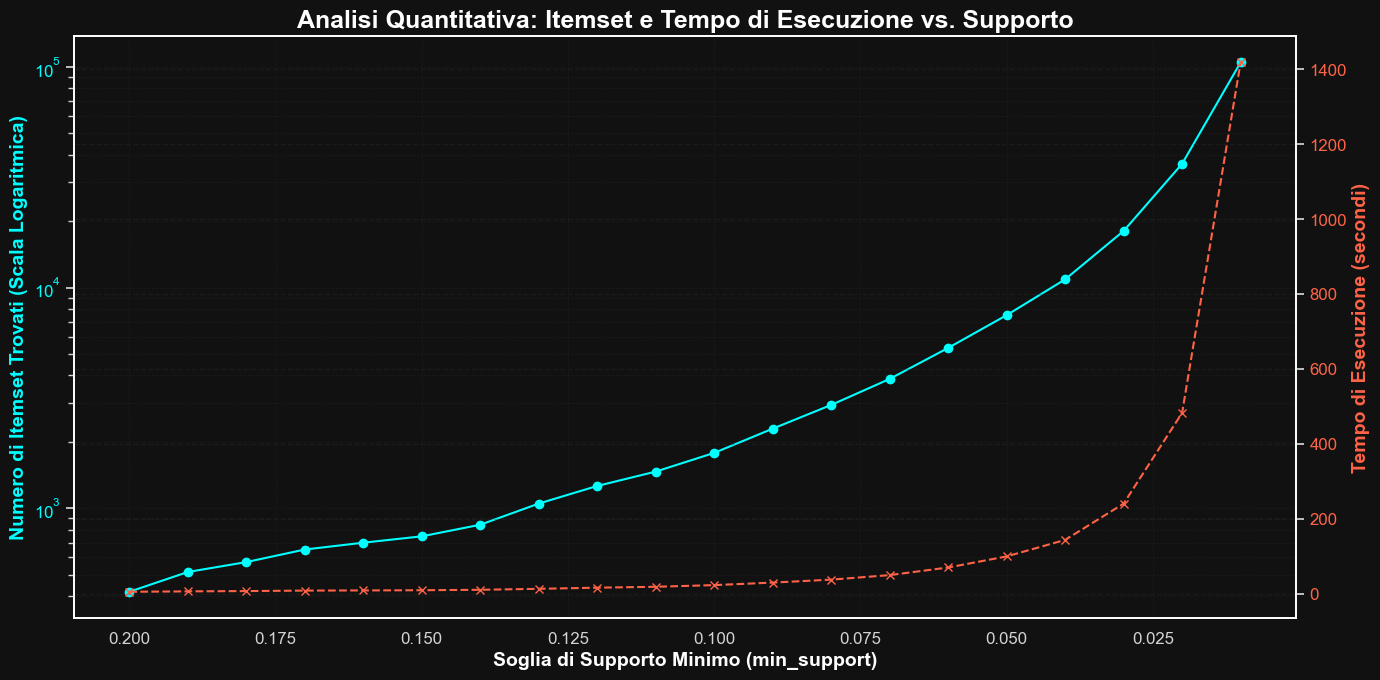

In [8]:
import time
from mlxtend.frequent_patterns import fpgrowth

# --- FASE 2: ANALISI QUANTITATIVA AL VARIARE DEL min_support ---

print("🚀 Inizio Fase 2: Analisi dei Frequent Pattern...")
print("🔹 Step 1/2: Analisi quantitativa (Supporto vs. Numero di Pattern)...")

# Definiamo un range di valori di supporto da testare.
# Partiamo da un valore relativamente alto e scendiamo per osservare la crescita.
# NOTA: questo processo può richiedere alcuni minuti a seconda del dataset.
support_thresholds = np.arange(0.20, 0.009, -0.01)
num_itemsets_found = []
execution_times = []

for support in support_thresholds:
    start_time = time.time()
    # Eseguiamo fpgrowth per ogni soglia
    frequent_itemsets = fpgrowth(transactional_df, min_support=support, use_colnames=True)
    end_time = time.time()

    num_found = len(frequent_itemsets)
    exec_time = end_time - start_time

    num_itemsets_found.append(num_found)
    execution_times.append(exec_time)
    print(f"  - min_support: {support:.2f} -> Trovati {num_found:6d} itemset in {exec_time:.2f} sec.")

# Creiamo un DataFrame per il plotting
support_analysis_df = pd.DataFrame({
    'min_support': support_thresholds,
    'num_itemsets': num_itemsets_found,
    'time_seconds': execution_times
})

print("\n✅ Analisi quantitativa completata.")

# --- PLOTTING DEI RISULTATI ---
print("📊 Generazione del grafico 'Numero Itemset vs. Supporto'...")

fig, ax1 = plt.subplots(figsize=(14, 7))

# Grafico principale: Numero di Itemset vs. Supporto
color = 'cyan'
ax1.set_xlabel('Soglia di Supporto Minimo (min_support)', fontsize=14)
ax1.set_ylabel('Numero di Itemset Trovati (Scala Logaritmica)', color=color, fontsize=14)
ax1.plot(support_analysis_df['min_support'], support_analysis_df['num_itemsets'], color=color, marker='o', label='Numero Itemset')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_yscale('log') # La scala logaritmica è essenziale per visualizzare la crescita esponenziale.
ax1.invert_xaxis() # Invertiamo l'asse x per una lettura più intuitiva (da supporto alto a basso)
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Aggiungiamo un secondo asse y per il tempo di esecuzione
ax2 = ax1.twinx()
color = 'tomato'
ax2.set_ylabel('Tempo di Esecuzione (secondi)', color=color, fontsize=14)
ax2.plot(support_analysis_df['min_support'], support_analysis_df['time_seconds'], color=color, marker='x', linestyle='--', label='Tempo Esecuzione')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Analisi Quantitativa: Itemset e Tempo di Esecuzione vs. Supporto', fontsize=18)
fig.tight_layout()

# Salviamo il grafico per il report
plot_filename = os.path.join(plots_dir, 'quantitative_itemsets_vs_support.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"✅ Grafico salvato in '{plot_filename}'")

plt.show()

#### Estrazione qualitativa dei frequent patterns con min_support = elbow value = 0.03

In [3]:
# --- FASE 2: ANALISI QUALITATIVA DEI FREQUENT PATTERN ---

print("🔹 Step 2/2: Estrazione e analisi qualitativa dei pattern...")

# Valore di supporto scelto sulla base dell'analisi quantitativa precedente
min_support_value = 0.03

print(f"--- Esecuzione di FP-Growth con min_support = {min_support_value} ---")
start_time = time.time()

# Eseguiamo l'algoritmo una sola volta
frequent_itemsets = fpgrowth(transactional_df, min_support=min_support_value, use_colnames=True)

end_time = time.time()
print(f"✅ Analisi completata in {end_time - start_time:.2f} secondi.")
print(f"📊 Trovati {len(frequent_itemsets)} itemset frequenti.")

# Aggiungiamo una colonna con la lunghezza di ogni itemset per analisi future
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))

# --- ISPEZIONE DEI RISULTATI ---
# Ordiniamo i risultati per supporto decrescente per vedere i più comuni
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False)

# Visualizziamo le prime righe del risultato finale
print("\n--- Top 15 Itemset più Frequenti (in generale) ---")
# Aumentiamo la larghezza di visualizzazione per leggere bene gli itemset
pd.set_option('display.max_colwidth', 120)
display(frequent_itemsets.head(15))

print("\n--- Top 15 Itemset più Frequenti con almeno 2 item ---")
# Filtriamo per avere solo le combinazioni di item
display(frequent_itemsets[frequent_itemsets['length'] >= 2].head(15))


# --- ANALISI MIRATA ALL'OBIETTIVO 🎯 ---
# Cerchiamo i pattern più frequenti che includono una vittoria di un premio.
# Questi sono i più interessanti per il nostro obiettivo predittivo.
print("\n💡 --- Top 15 Pattern Frequenti che includono 'target_hasWon_True' ---")
won_patterns = frequent_itemsets[frequent_itemsets['itemsets'].apply(lambda x: 'target_hasWon_True' in x)]
display(won_patterns.head(15))

🔹 Step 2/2: Estrazione e analisi qualitativa dei pattern...
--- Esecuzione di FP-Growth con min_support = 0.03 ---
✅ Analisi completata in 230.21 secondi.
📊 Trovati 18031 itemset frequenti.

--- Top 15 Itemset più Frequenti (in generale) ---


,support,itemsets,length
0,1.000000,(_awardNominationsExcludeWins_None),1
54,1.000000,"(_totalVideos_None, _awardNominationsExcludeWins_None)",2
1,1.000000,(_totalVideos_None),1
55,0.868986,"(_totalVideos_None, target_hasWon_False)",2
2,0.868986,(target_hasWon_False),1
56,0.868986,"(target_hasWon_False, _awardNominationsExcludeWins_None)",2
57,0.868986,"(_totalVideos_None, target_hasWon_False, _awardNominationsExcludeWins_None)",3
58,0.811775,"(_criticReviewsTotal_Low, _totalVideos_None)",2
59,0.811775,"(_criticReviewsTotal_Low, _awardNominationsExcludeWins_None)",2
61,0.811775,"(_criticReviewsTotal_Low, _totalVideos_None, _awardNominationsExcludeWins_None)",3



--- Top 15 Itemset più Frequenti con almeno 2 item ---


,support,itemsets,length
54,1.000000,"(_totalVideos_None, _awardNominationsExcludeWins_None)",2
55,0.868986,"(_totalVideos_None, target_hasWon_False)",2
56,0.868986,"(target_hasWon_False, _awardNominationsExcludeWins_None)",2
57,0.868986,"(_totalVideos_None, target_hasWon_False, _awardNominationsExcludeWins_None)",3
58,0.811775,"(_criticReviewsTotal_Low, _totalVideos_None)",2
59,0.811775,"(_criticReviewsTotal_Low, _awardNominationsExcludeWins_None)",2
61,0.811775,"(_criticReviewsTotal_Low, _totalVideos_None, _awardNominationsExcludeWins_None)",3
65,0.784932,"(_userReviewsTotal_Low, _totalVideos_None)",2
66,0.784932,"(_userReviewsTotal_Low, _awardNominationsExcludeWins_None)",2
69,0.784932,"(_userReviewsTotal_Low, _totalVideos_None, _awardNominationsExcludeWins_None)",3



💡 --- Top 15 Pattern Frequenti che includono 'target_hasWon_True' ---


,support,itemsets,length
14129,0.131014,"(target_hasWon_True, _awardNominationsExcludeWins_None)",2
14128,0.131014,"(target_hasWon_True, _totalVideos_None)",2
14145,0.131014,"(target_hasWon_True, _totalVideos_None, _awardNominationsExcludeWins_None)",3
37,0.131014,(target_hasWon_True),1
14171,0.081491,"(target_hasWon_True, titleType_movie, _awardNominationsExcludeWins_None)",3
14173,0.081491,"(target_hasWon_True, _totalVideos_None, titleType_movie, _awardNominationsExcludeWins_None)",4
14133,0.081491,"(target_hasWon_True, titleType_movie)",2
14172,0.081491,"(target_hasWon_True, _totalVideos_None, titleType_movie)",3
14140,0.070985,"(target_hasWon_True, genres_Drama)",2
14393,0.070985,"(target_hasWon_True, _totalVideos_None, genres_Drama)",3


In [5]:
won_patterns

,support,itemsets,length
14129,0.131014,"(target_hasWon_True, _awardNominationsExcludeWins_None)",2
14128,0.131014,"(target_hasWon_True, _totalVideos_None)",2
14145,0.131014,"(target_hasWon_True, _totalVideos_None, _awardNominationsExcludeWins_None)",3
37,0.131014,(target_hasWon_True),1
14171,0.081491,"(target_hasWon_True, titleType_movie, _awardNominationsExcludeWins_None)",3
...,...,...,...
14463,0.030239,"(target_hasWon_True, _criticReviewsTotal_Medium, titleType_movie, _awardNominationsExcludeWins_None, _totalVideos_No...",8
14232,0.030047,"(target_hasWon_True, titleType_movie, _awardNominationsExcludeWins_None, genres_Drama, _totalVideos_None, _userRevie...",6
14227,0.030047,"(genres_Drama, target_hasWon_True, _userReviewsTotal_Medium, titleType_movie)",4
14230,0.030047,"(titleType_movie, target_hasWon_True, _awardNominationsExcludeWins_None, genres_Drama, _userReviewsTotal_Medium)",5


#### PREDICTIVE ASSOCIATION RULES EXTRACTION

In [8]:
from mlxtend.frequent_patterns import association_rules

# --- FASE 3: ESTRAZIONE DELLE REGOLE DI ASSOCIAZIONE (v2 - SOGLIA RICALIBRATA) ---

print("🚀 Inizio Fase 3 (v2): Estrazione Regole con Soglia Ricalibrata...")

# --- 1. PULIZIA DEI FREQUENT ITEMSETS (come prima) ---
useless_items = {'_totalVideos_None', '_awardNominationsExcludeWins_None'}
original_count = len(frequent_itemsets)
frequent_itemsets_cleaned = frequent_itemsets[frequent_itemsets['itemsets'].apply(lambda x: x.isdisjoint(useless_items))]
cleaned_count = len(frequent_itemsets_cleaned)
print(f"🧹 Pulizia dei pattern: rimossi {original_count - cleaned_count} pattern.")
print(f"Rimangono {cleaned_count} pattern puliti su cui generare le regole.")


# --- 2. GENERAZIONE E FILTRO DELLE REGOLE (CON NUOVA SOGLIA) ---
#
# ABBASSIAMO DRASTICAMENTE LA SOGLIA DI CONFIDENZA PER CATTURARE
# LE REGOLE CHE PREDICONO UN EVENTO RARO COME UNA VITTORIA.
#
min_confidence_value = 0.25  # Soglia abbassata da 0.6 a 0.25

print(f"\n--- Generazione delle regole con min_confidence >= {min_confidence_value} ---")
rules = association_rules(frequent_itemsets_cleaned, metric='confidence', min_threshold=min_confidence_value)
print(f"Trovate {len(rules)} regole associative totali.")


# --- 3. FILTRO PER REGOLE PREDITTIVE (come prima) ---
target_items = ['target_hasWon_True', 'target_hasWon_False']
predictive_rules = rules[rules['consequents'].apply(lambda c: list(c) in [['target_hasWon_True'], ['target_hasWon_False']])]
print(f"Di queste, {len(predictive_rules)} sono regole predittive per 'hasWon'.")

# Ordiniamo per LIFT e poi CONFIDENZA per vedere le regole più "potenti"
predictive_rules = predictive_rules.sort_values(by=['lift', 'confidence'], ascending=False)


# --- VISUALIZZAZIONE DELLE REGOLE PIÙ FORTI PER PREDIRE UNA VITTORIA ---
print("\n🎯 --- Top 15 Regole più Forti per Predire 'target_hasWon_True' ---")
rules_predicting_win = predictive_rules[predictive_rules['consequents'] == {'target_hasWon_True'}]

# Stampiamo le colonne più importanti per la nostra valutazione
display(rules_predicting_win[['antecedents', 'consequents', 'confidence', 'lift', 'support']].head(20))

🚀 Inizio Fase 3 (v2): Estrazione Regole con Soglia Ricalibrata...
🧹 Pulizia dei pattern: rimossi 13524 pattern.
Rimangono 4507 pattern puliti su cui generare le regole.

--- Generazione delle regole con min_confidence >= 0.25 ---
Trovate 39035 regole associative totali.
Di queste, 2042 sono regole predittive per 'hasWon'.

🎯 --- Top 15 Regole più Forti per Predire 'target_hasWon_True' ---


,antecedents,consequents,confidence,lift,support
36681,"(titleType_movie, genres_Drama, _numVotes_VeryHigh)",(target_hasWon_True),0.571093,4.359016,0.031136
34241,"(titleType_movie, _criticReviewsTotal_Medium, genres_Drama)",(target_hasWon_True),0.526590,4.019338,0.032353
37214,"(titleType_movie, _totalCredits_VeryHigh, _numVotes_VeryHigh)",(target_hasWon_True),0.525739,4.012844,0.030751
37923,"(titleType_movie, _criticReviewsTotal_Medium, _totalCredits_VeryHigh)",(target_hasWon_True),0.517993,3.953721,0.030431
38271,"(titleType_movie, _criticReviewsTotal_Medium, _numVotes_VeryHigh, _totalImages_Many, _userReviewsTotal_Medium)",(target_hasWon_True),0.508073,3.878002,0.030239
38001,"(_runtimeMinutes_VeryLong, titleType_movie, _criticReviewsTotal_Medium, _numVotes_VeryHigh)",(target_hasWon_True),0.508039,3.877738,0.030367
35684,"(titleType_movie, _criticReviewsTotal_Medium, _numVotes_VeryHigh, _totalImages_Many)",(target_hasWon_True),0.503553,3.843503,0.031777
39028,"(_userReviewsTotal_Medium, titleType_movie, genres_Drama)",(target_hasWon_True),0.503219,3.840950,0.030047
38167,"(_runtimeMinutes_VeryLong, titleType_movie, _userReviewsTotal_Medium, _numVotes_VeryHigh)",(target_hasWon_True),0.502657,3.836660,0.030303
35080,"(titleType_movie, _userReviewsTotal_Medium, _numVotes_VeryHigh, _totalImages_Many)",(target_hasWon_True),0.495540,3.782340,0.032033


In [21]:
rules_predicting_win

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
36681,"(titleType_movie, genres_Drama, _numVotes_VeryHigh)",(target_hasWon_True),0.054520,0.131014,0.031136,0.571093,4.359016,1.0,0.023993,2.026046,0.815025,0.201660,0.506428,0.404373
34241,"(titleType_movie, _criticReviewsTotal_Medium, genres_Drama)",(target_hasWon_True),0.061439,0.131014,0.032353,0.526590,4.019338,1.0,0.024304,1.835589,0.800377,0.202081,0.455216,0.386767
37214,"(titleType_movie, _totalCredits_VeryHigh, _numVotes_VeryHigh)",(target_hasWon_True),0.058492,0.131014,0.030751,0.525739,4.012844,1.0,0.023088,1.832296,0.797444,0.193705,0.454237,0.380229
37923,"(titleType_movie, _criticReviewsTotal_Medium, _totalCredits_VeryHigh)",(target_hasWon_True),0.058748,0.131014,0.030431,0.517993,3.953721,1.0,0.022734,1.802851,0.793702,0.190993,0.445323,0.375134
38271,"(titleType_movie, _criticReviewsTotal_Medium, _numVotes_VeryHigh, _totalImages_Many, _userReviewsTotal_Medium)",(target_hasWon_True),0.059517,0.131014,0.030239,0.508073,3.878002,1.0,0.022441,1.766494,0.789100,0.188649,0.433907,0.369440
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10500,"(_runtimeMinutes_VeryLong, titleType_movie)",(target_hasWon_True),0.194439,0.131014,0.056634,0.291269,2.223184,1.0,0.031160,1.226114,0.682996,0.210677,0.184415,0.361771
8181,(_userReviewsTotal_Medium),(target_hasWon_True),0.215068,0.131014,0.062272,0.289544,2.210022,1.0,0.034095,1.223139,0.697533,0.219413,0.182431,0.382425
9226,(_totalImages_Many),(target_hasWon_True),0.231341,0.131014,0.059645,0.257823,1.967904,1.0,0.029336,1.170861,0.639874,0.197037,0.145928,0.356540
35810,"(genres_Drama, _totalCredits_VeryHigh)",(target_hasWon_True),0.122942,0.131014,0.031648,0.257426,1.964870,1.0,0.015541,1.170234,0.559895,0.142363,0.145470,0.249495


#### PRE-PROCESSING FOR THE TEST SET

In [11]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

def preprocess_dataframe(df):
    """
    Applica l'intero processo di preprocessing a un DataFrame per renderlo transazionale.
    Questa funzione incapsula la logica usata per df_train per garantirne la coerenza.
    """
    print(f"--- Inizio preprocessing per un DataFrame di {df.shape[0]} righe ---")

    # Crea una copia per non modificare l'originale
    df_pm = df.copy()

    # 1. Definizione della variabile target
    df_pm['hasWon'] = df_pm['awardWins'] > 0
    y_true = df_pm['hasWon'] # Salviamo le etichette reali prima del one-hot

    # 2. Discretizzazione delle variabili numeriche
    numerical_cols_to_discretize = {
        'startYear': {'q': [1900, 1960, 1980, 1990, 2000, 2010, 2025], 'labels': ['Before_1960', '60s-70s', '80s', '90s', '2000s', '2010s+']},
        'runtimeMinutes': {'q': 4, 'labels': ['Short', 'Medium', 'Long', 'VeryLong']},
        'numVotes': {'q': 5, 'labels': ['VeryLow', 'Low', 'Medium', 'High', 'VeryHigh']},
        'totalImages': {'q': 4, 'labels': ['None', 'Few', 'Some', 'Many']},
        'totalVideos': {'q': 3, 'labels': ['None', 'Few', 'Many']},
        'totalCredits': {'q': 4, 'labels': ['Low', 'Medium', 'High', 'VeryHigh']},
        'criticReviewsTotal': {'q': 4, 'labels': ['Low', 'Medium', 'High', 'VeryHigh']},
        'userReviewsTotal': {'q': 4, 'labels': ['Low', 'Medium', 'High', 'VeryHigh']},
        'awardNominationsExcludeWins': {'q': 4, 'labels': ['None', 'Few', 'Some', 'Many']}
    }

    binned_cols = []
    for col, params in numerical_cols_to_discretize.items():
        new_col_name = f'_{col}'
        try:
            if isinstance(params['q'], int):
                binned_series = pd.qcut(df_pm[col], q=params['q'], duplicates='drop')
                category_mapping = {interval: params['labels'][i] for i, interval in enumerate(binned_series.cat.categories)}
                df_pm[new_col_name] = binned_series.cat.rename_categories(category_mapping)
            else:
                df_pm[new_col_name] = pd.cut(df_pm[col], bins=params['q'], labels=params['labels'], right=False)
            binned_cols.append(new_col_name)
        except Exception as e:
            print(f"  - ❌ ATTENZIONE: Impossibile discretizzare la colonna '{col}'. Errore: {e}")

    # 3. One-Hot Encoding e selezione colonne
    binned_one_hot = pd.get_dummies(df_pm[binned_cols])
    existing_one_hot_cols = [col for col in df.columns if 'titleType_' in col or 'genres_' in col or 'countryOfOrigin_' in col]
    existing_one_hot_df = df[existing_one_hot_cols]

    # 4. Unione e finalizzazione
    # NOTA: non includiamo il target nel df transazionale, lo teniamo separato in y_true.
    X_trans = pd.concat([binned_one_hot, existing_one_hot_df], axis=1)

    # Assicuriamoci che tutte le colonne presenti nel training transazionale esistano anche qui
    # e che l'ordine sia lo stesso. Aggiungiamo eventuali colonne mancanti con valore False.
    # `transactional_df` è il df creato dal training set nella Cella 2
    global transactional_df
    missing_cols = set(transactional_df.columns) - set(X_trans.columns)
    for c in missing_cols:
        if 'target_hasWon' not in c: # Escludiamo le colonne target
             X_trans[c] = False
    X_trans = X_trans[transactional_df.drop(columns=['target_hasWon_True', 'target_hasWon_False']).columns]

    print(f"✅ Preprocessing completato. DataFrame finale con {X_trans.shape[1]} features.")
    return X_trans.astype(bool), y_true

# --- APPLICAZIONE SUL TEST SET ---
# Ora usiamo la funzione per processare il nostro df_test
X_test_trans, y_test = preprocess_dataframe(df_test)

--- Inizio preprocessing per un DataFrame di 5478 righe ---
✅ Preprocessing completato. DataFrame finale con 59 features.


In [16]:
# Cella di controllo
print("--- Controllo Allineamento DataFrame ---")

# Colonne del training set (su cui abbiamo estratto le regole)
train_cols = transactional_df.drop(columns=['target_hasWon_True', 'target_hasWon_False']).columns

# Colonne del test set (che daremo in pasto al classificatore)
test_cols = X_test_trans.columns

print(f"Numero colonne Training Set (features): {len(train_cols)}")
print(f"Numero colonne Test Set (features):   {len(test_cols)}")
print(f"Le colonne sono identiche in numero e ordine? -> {all(train_cols == test_cols)}")

--- Controllo Allineamento DataFrame ---
Numero colonne Training Set (features): 59
Numero colonne Test Set (features):   59
Le colonne sono identiche in numero e ordine? -> True


In [14]:
X_test_trans

,_startYear_Before_1960,_startYear_60s-70s,_startYear_80s,_startYear_90s,_startYear_2000s,_startYear_2010s+,_runtimeMinutes_Short,_runtimeMinutes_Medium,_runtimeMinutes_Long,_runtimeMinutes_VeryLong,...,countryOfOrigin_US,countryOfOrigin_GB,countryOfOrigin_JP,countryOfOrigin_FR,countryOfOrigin_CA,countryOfOrigin_IN,countryOfOrigin_DE,countryOfOrigin_IT,countryOfOrigin_ES,countryOfOrigin_AU
0,False,False,False,False,False,True,True,False,False,False,...,True,False,False,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,True,False,False,...,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,True,False,True,False,False,...,False,True,False,False,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,True,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5473,False,False,False,True,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
5474,False,False,False,True,False,False,True,False,False,False,...,True,False,False,False,False,False,False,False,False,False
5475,False,False,True,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
5476,False,False,False,False,False,True,False,True,False,False,...,True,False,False,False,False,False,False,False,False,False


In [15]:
X_test_trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 59 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   _startYear_Before_1960             5478 non-null   bool 
 1   _startYear_60s-70s                 5478 non-null   bool 
 2   _startYear_80s                     5478 non-null   bool 
 3   _startYear_90s                     5478 non-null   bool 
 4   _startYear_2000s                   5478 non-null   bool 
 5   _startYear_2010s+                  5478 non-null   bool 
 6   _runtimeMinutes_Short              5478 non-null   bool 
 7   _runtimeMinutes_Medium             5478 non-null   bool 
 8   _runtimeMinutes_Long               5478 non-null   bool 
 9   _runtimeMinutes_VeryLong           5478 non-null   bool 
 10  _numVotes_VeryLow                  5478 non-null   bool 
 11  _numVotes_Low                      5478 non-null   bool 
 12  _numVotes_Medium    

### RULE-BASED CLASSIFICATOR

In [12]:
# --- FASE 4: DEFINIZIONE E APPLICAZIONE DEL CLASSIFICATORE ---

class RuleBasedClassifier:
    """
    Un classificatore che utilizza un set di regole di associazione per fare predizioni.
    Le regole devono predire un esito 'True'. Se nessuna regola corrisponde,
    la predizione di default è 'False'.
    """
    def __init__(self, rules):
        # Le regole in input sono già filtrate per predire solo 'True'
        # e ordinate per confidence e lift, le più forti sono in cima.
        self.rules = rules.copy()
        # Trasformiamo gli antecedenti in 'frozenset' per confronti veloci
        self.rules['antecedents'] = self.rules['antecedents'].apply(lambda x: frozenset(x))
        print(f"Classificatore inizializzato con {len(self.rules)} regole.")

    def predict(self, X_trans):
        """
        Esegue le predizioni su un DataFrame transazionale.
        """
        print(f" Inizio predizione su {len(X_trans)} campioni...")
        predictions = []
        for i, row in X_trans.iterrows():
            # Otteniamo l'insieme di item per il film corrente
            transaction_items = set(row[row].index)

            # Cerchiamo la prima regola (la più forte) il cui antecedente
            # è un sottoinsieme degli item del film.
            prediction = False # Predizione di default
            for _, rule in self.rules.iterrows():
                if rule['antecedents'].issubset(transaction_items):
                    # Trovata una regola corrispondente! La predizione è True.
                    # Poiché le regole sono ordinate, la prima che troviamo è la migliore.
                    prediction = True
                    break # Interrompiamo il ciclo per efficienza

            predictions.append(prediction)

        print(" Predizione completata.")
        return pd.Series(predictions, index=X_trans.index)

# --- CREAZIONE E APPLICAZIONE DEL MODELLO ---
# `rules_predicting_win` è il DataFrame con le nostre 75 regole d'oro dalla Cella 5

# Creiamo un'istanza del nostro classificatore
rb_classifier = RuleBasedClassifier(rules=rules_predicting_win)

# Eseguiamo la predizione sul test set
y_pred = rb_classifier.predict(X_test_trans)

✅ Classificatore inizializzato con 75 regole.
▶️  Inizio predizione su 5478 campioni...
✅ Predizione completata.


#### Performance Metrics

🏆 Inizio valutazione delle performance sul Test Set...

--- Metriche di Performance ---
  - Accuracy:  51.41%
  - Precision: 17.95%
  - Recall:    81.11%
  - F1-Score:  29.39%

✅ Grafico Matrice di Confusione salvato in 'plots_pattern_mining/confusion_matrix.png'


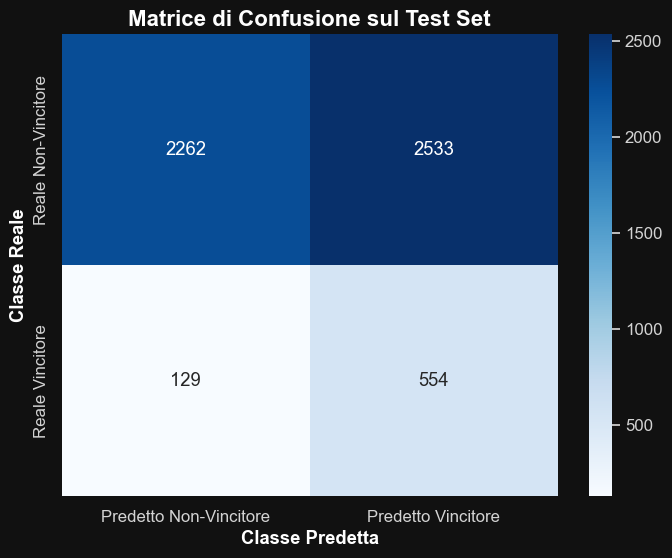


--- Report di Classificazione Completo ---
              precision    recall  f1-score   support

hasWon=False       0.95      0.47      0.63      4795
 hasWon=True       0.18      0.81      0.29       683

    accuracy                           0.51      5478
   macro avg       0.56      0.64      0.46      5478
weighted avg       0.85      0.51      0.59      5478



In [13]:
# --- FASE 4: VALUTAZIONE DELLE PERFORMANCE ---

print(" Inizio valutazione delle performance sul Test Set...")

# 1. Calcolo delle metriche
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n--- Metriche di Performance ---")
print(f"  - Accuracy:  {accuracy:.2%}")
print(f"  - Precision: {precision:.2%}")
print(f"  - Recall:    {recall:.2%}")
print(f"  - F1-Score:  {f1:.2%}")

# 2. Matrice di Confusione
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predetto Non-Vincitore', 'Predetto Vincitore'],
            yticklabels=['Reale Non-Vincitore', 'Reale Vincitore'])
plt.title('Matrice di Confusione sul Test Set', fontsize=16)
plt.ylabel('Classe Reale')
plt.xlabel('Classe Predetta')

# Salviamo il grafico per il report
plot_filename = os.path.join(plots_dir, 'confusion_matrix.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"\n Grafico Matrice di Confusione salvato in '{plot_filename}'")
plt.show()


# 3. Classification Report completo
print("\n--- Report di Classificazione Completo ---")
print(classification_report(y_test, y_pred, target_names=['hasWon=False', 'hasWon=True'], zero_division=0))

In [ ]:
#### Classificatore 2 regolato diversamente

In [17]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# --- FASE 4.1: MIGLIORAMENTO DEL CLASSIFICATORE ---

class RuleBasedClassifierV2:
    """
    Versione 2 del classificatore.
    Aggiunge un parametro 'confidence_threshold' per rendere il modello più selettivo.
    """
    def __init__(self, rules, confidence_threshold=0.0):
        self.rules = rules.copy()
        self.rules['antecedents'] = self.rules['antecedents'].apply(lambda x: frozenset(x))
        # La nuova soglia di confidenza
        self.confidence_threshold = confidence_threshold
        print(f"✅ Classificatore V2 inizializzato con {len(self.rules)} regole e soglia di confidenza >= {self.confidence_threshold:.2f}.")

    def predict(self, X_trans):
        """ Esegue le predizioni su un DataFrame transazionale. """
        predictions = []
        for i, row in X_trans.iterrows():
            transaction_items = set(row[row].index)
            prediction = False
            for _, rule in self.rules.iterrows():
                # LA NUOVA LOGICA:
                # Controlla se la regola corrisponde E se la sua confidenza supera la nostra soglia.
                if rule['antecedents'].issubset(transaction_items) and rule['confidence'] >= self.confidence_threshold:
                    prediction = True
                    break
            predictions.append(prediction)
        return pd.Series(predictions, index=X_trans.index)

# --- ANALISI DEL TRADE-OFF PRECISIONE-RECALL ---
print("🚀 Inizio analisi trade-off Precisione-Recall...")

# Definiamo le soglie di confidenza da testare
thresholds = np.arange(0.25, 0.60, 0.05)
precision_scores = []
recall_scores = []

# y_test è stato definito nella Cella 6
# X_test_trans è stato definito nella Cella 6
# rules_predicting_win è stato definito nella Cella 5 (versione corretta)

for thresh in thresholds:
    # 1. Crea un'istanza del classificatore con la soglia corrente
    rbc_v2 = RuleBasedClassifierV2(rules=rules_predicting_win, confidence_threshold=thresh)

    # 2. Esegui la predizione
    y_pred_v2 = rbc_v2.predict(X_test_trans)

    # 3. Calcola le metriche per la classe 'True'
    precision = precision_score(y_test, y_pred_v2, zero_division=0)
    recall = recall_score(y_test, y_pred_v2, zero_division=0)

    precision_scores.append(precision)
    recall_scores.append(recall)

    print(f"  - Risultati per soglia >= {thresh:.2f}: Precision={precision:.2%}, Recall={recall:.2%}")

print("\n✅ Analisi trade-off completata.")

# Creiamo un DataFrame con i risultati per il plotting
tradeoff_df = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision_scores,
    'recall': recall_scores
})

🚀 Inizio analisi trade-off Precisione-Recall...
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.25.
  - Risultati per soglia >= 0.25: Precision=17.95%, Recall=81.11%
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.30.
  - Risultati per soglia >= 0.30: Precision=21.21%, Recall=75.84%
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.35.
  - Risultati per soglia >= 0.35: Precision=23.40%, Recall=71.74%
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.40.
  - Risultati per soglia >= 0.40: Precision=27.20%, Recall=62.81%
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.45.
  - Risultati per soglia >= 0.45: Precision=33.27%, Recall=53.73%
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.50.
  - Risultati per soglia >= 0.50: Precision=40.36%, Recall=39.53%
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.


📊 Generazione del grafico di trade-off...
✅ Grafico trade-off salvato in 'plots_pattern_mining/precision_recall_tradeoff.png'


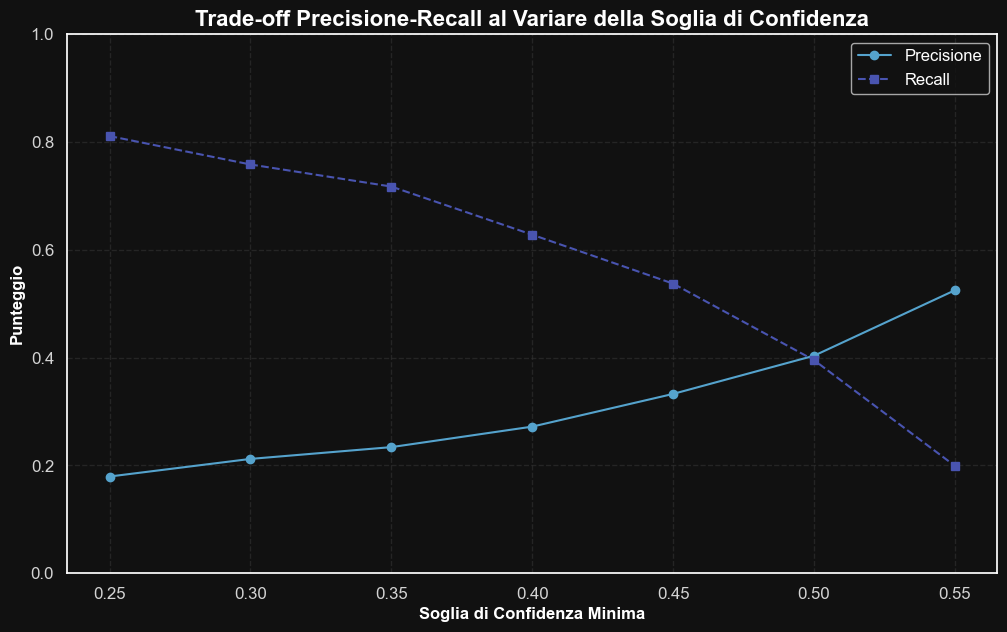

,threshold,precision,recall
0,0.25,0.179462,0.811127
1,0.30,0.212121,0.758419
2,0.35,0.234002,0.717423
3,0.40,0.272036,0.628111
4,0.45,0.332729,0.537335
5,0.50,0.403587,0.395315
6,0.55,0.525097,0.199122


In [18]:
# --- FASE 4.2: VISUALIZZAZIONE DEL TRADE-OFF ---
print("\n📊 Generazione del grafico di trade-off...")

plt.figure(figsize=(12, 7))

plt.plot(tradeoff_df['threshold'], tradeoff_df['precision'], marker='o', linestyle='-', label='Precisione')
plt.plot(tradeoff_df['threshold'], tradeoff_df['recall'], marker='s', linestyle='--', label='Recall')

plt.title('Trade-off Precisione-Recall al Variare della Soglia di Confidenza', fontsize=16)
plt.xlabel('Soglia di Confidenza Minima', fontsize=12)
plt.ylabel('Punteggio', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0, 1) # Assi Y da 0 a 1 (0% a 100%)
plt.xticks(thresholds) # Mostra tutte le nostre soglie sull'asse X

# Salviamo il grafico per il report
plot_filename = os.path.join(plots_dir, 'precision_recall_tradeoff.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"✅ Grafico trade-off salvato in '{plot_filename}'")
plt.show()

display(tradeoff_df)

🏆 Inizio valutazione del modello V2 ottimizzato...
✅ Classificatore V2 inizializzato con 75 regole e soglia di confidenza >= 0.50.

--- Report di Classificazione Completo (Modello V2 Ottimizzato) ---
              precision    recall  f1-score   support

hasWon=False       0.91      0.92      0.92      4795
 hasWon=True       0.40      0.40      0.40       683

    accuracy                           0.85      5478
   macro avg       0.66      0.66      0.66      5478
weighted avg       0.85      0.85      0.85      5478


--- Matrice di Confusione (Modello V2 Ottimizzato) ---
[[4396  399]
 [ 413  270]]

✅ Grafico Matrice di Confusione Ottimizzata salvato in 'plots_pattern_mining/confusion_matrix_optimized.png'


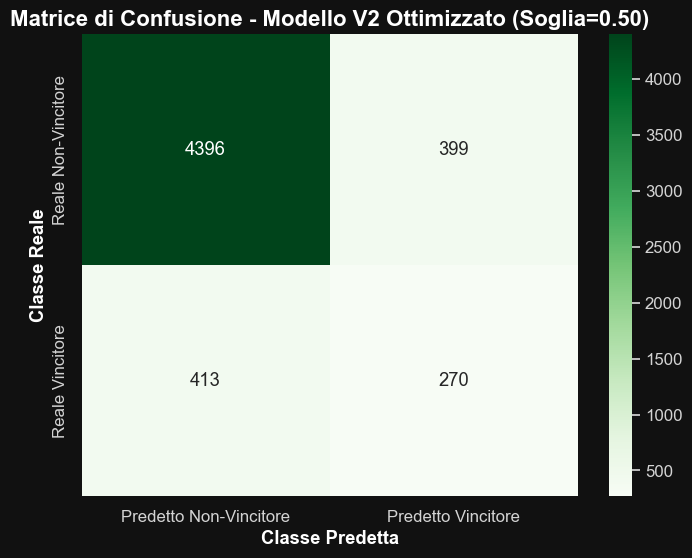

In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# --- Valutazione del Modello V2 Ottimizzato ("Balanced Judge") ---

print("🏆 Inizio valutazione del modello V2 ottimizzato...")

# Impostiamo la soglia di confidenza ottimale a 0.50, come identificato
# dalla nostra analisi di trade-off.
optimal_threshold = 0.50

# 1. Creiamo un'istanza del classificatore con la soglia ottimale
#    La classe RuleBasedClassifierV2 deve essere stata definita in una cella precedente.
#    `rules_predicting_win` è il DataFrame con le regole che predicono True.
#    `X_test_trans` e `y_test` sono il nostro test set processato.
rbc_optimized = RuleBasedClassifierV2(rules=rules_predicting_win, confidence_threshold=optimal_threshold)

# 2. Eseguiamo la predizione sul test set
y_pred_optimized = rbc_optimized.predict(X_test_trans)

# 3. Calcoliamo e stampiamo il report di classificazione completo
#    Questo mostrerà i valori di 0.40 e 0.91 che vedi nel report.
print("\n--- Report di Classificazione Completo (Modello V2 Ottimizzato) ---")
print(classification_report(y_test, y_pred_optimized, target_names=['hasWon=False', 'hasWon=True'], zero_division=0))


# 4. Calcoliamo e visualizziamo la matrice di confusione per il modello ottimizzato
print("\n--- Matrice di Confusione (Modello V2 Ottimizzato) ---")
cm_optimized = confusion_matrix(y_test, y_pred_optimized)

# Stampa la matrice di confusione per un controllo numerico
print(cm_optimized)

# Visualizzazione grafica
plt.figure(figsize=(8, 6))
sns.heatmap(cm_optimized, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Predetto Non-Vincitore', 'Predetto Vincitore'],
            yticklabels=['Reale Non-Vincitore', 'Reale Vincitore'])
plt.title('Matrice di Confusione - Modello V2 Ottimizzato (Soglia=0.50)', fontsize=16)
plt.ylabel('Classe Reale')
plt.xlabel('Classe Predetta')

# Salviamo il nuovo grafico
plot_filename = os.path.join(plots_dir, 'confusion_matrix_optimized.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"\n✅ Grafico Matrice di Confusione Ottimizzata salvato in '{plot_filename}'")
plt.show()